<a href="https://colab.research.google.com/github/nkordylewicz/ML-for-space-applications/blob/main/Lab3_ML_Bayes_kNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 3: Bayes' and k-NN classifier from scratch

**Colour code in all result maps:** 🟥 **red = forest**, 🟦 **blue = urban**.

**Data.** Sentinel-2 L2A from **Microsoft Planetary Computer**, the same as in previous Lab. The study areas are Kraków (urban), the Niepołomice Forest and the Wolski Forest (forest).

| Section | Content |
|---|---|
| 0 | Setup and data access |
| 1.1 | Hand-crafted training and test areas |
| 1.2 | Histograms → parametric PDF models → parameter estimation |
| 1.3 | The Bayes test |
| 1.4 | Results on the test areas and on a new image |
| 2.1–2.3 | k-NN classifier |
| 2.4 | k = 1 vs 3 vs 5: comparison and comments |
| 3 | Bayes vs. k-NN summary |

## 0. Setup and data access

In [1]:
!pip install -q pystac-client planetary-computer odc-stac

In [2]:
import time
import numpy as np
import matplotlib.pyplot as mp
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch, Rectangle
import pystac_client, planetary_computer, odc.stac
from shapely.geometry import shape, box

rng = np.random.default_rng(42)

FOREST, URBAN = 0, 1
CLASS_NAMES = ["forest", "urban"]
CMAP_CLS = ListedColormap(["red", "blue"])
LEGEND = [Patch(color="red", label="forest"), Patch(color="blue", label="urban")]

S2_BANDS = ["B02", "B03", "B04", "B08"]
BAND_LABEL = {"B02": "B02 (blue)", "B03": "B03 (green)", "B04": "B04 (red)", "B08": "B08 (NIR)"}

# Access the data
catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace)

full_bbox = [19.82, 49.99, 20.45, 50.095]

def pick_item(collection, date_range, bbox=full_bbox, extra_query=None, sort_key=None):
    items = catalog.search(collections=[collection], bbox=bbox,
                           datetime=date_range, query=extra_query).item_collection()
    items = [it for it in items if shape(it.geometry).contains(box(*bbox))]
    if not items:
        raise ValueError(f"No {collection} scene fully covers {bbox}")
    if sort_key: items.sort(key=sort_key)
    return items[0]

s2_item = pick_item("sentinel-2-l2a", "2026-05-01/2026-09-30",
                    extra_query={"eo:cloud_cover": {"lt": 5}},
                    sort_key=lambda it: it.properties["eo:cloud_cover"])
print(s2_item.id, s2_item.properties["eo:cloud_cover"], "% clouds")

def load_s2(bb, **kw):
    ds = odc.stac.load([s2_item], bands=S2_BANDS, bbox=bb, resolution=kw.pop("resolution", 10), **kw).isel(time=0)
    return np.dstack([np.where(ds[b].values > 0, (ds[b].values.astype(float) - 1000) / 10000, np.nan)
                      for b in S2_BANDS])

def to_rgb(cube, gain=1 / 0.25):
    return np.clip(cube[..., [2, 1, 0]] * gain, 0, 1)

S2B_MSIL2A_20260503T094029_R036_T34UDA_20260503T115712 0.000514 % clouds


---
# Part 1: Bayes' classifier

## 1.1 Hand-crafted training and test areas

The Bayes classifier needs class-conditional PDFs $p(\mathbf{x}\mid\omega_i)$ estimated from samples that only contain one class. The small rectangles (about 360 m × 330 m, roughly 1 200 pixels each) that contain only one type of pixel were cut out.

* **urban:** densely built-up blocks of Kraków (roofs, streets, squares);
* **forest:** closed canopy. Most rectangles are in the Niepołomice Forest. Two are in the Wolski Forest.


In [3]:
# (lon_min, lat_min, lon_max, lat_max)
ROIS = {
    "train": {
        "forest": [[20.428, 50.020, 20.433, 50.023], [20.337, 50.051, 20.342, 50.054],
                   [20.417, 50.006, 20.422, 50.009], [20.308, 50.035, 20.313, 50.038],
                   [20.312, 50.025, 20.317, 50.028], [20.330, 50.042, 20.335, 50.045]],
        "urban":  [[19.944, 50.069, 19.949, 50.072], [20.007, 50.031, 20.012, 50.034],
                   [19.977, 50.067, 19.982, 50.070], [19.945, 50.054, 19.950, 50.057],
                   [19.971, 50.046, 19.976, 50.049], [19.934, 50.06, 19.939, 50.063]]},
    "test": {
        "forest": [[20.424, 50.029, 20.429, 50.032], [20.417, 50.031, 20.422, 50.034],     # Niepołomice
                   [20.319, 50.026, 20.324, 50.029],
                   [19.833, 50.049, 19.838, 50.052], [19.845, 50.045, 19.850, 50.048]],    # Wolski Forest
        "urban":  [[19.980, 50.087, 19.985, 50.090], [20.005, 50.059, 20.010, 50.062],
                   [20.005, 50.052, 20.010, 50.055], [19.893, 50.086, 19.898, 50.089]]},
}

def roi_pixels(bbs):
    cubes = [load_s2(bb) for bb in bbs]
    X = np.vstack([c.reshape(-1, 4) for c in cubes])
    return cubes, X[~np.isnan(X).any(axis=1)]

t0 = time.time()
cubes, X = {}, {}
for split in ["train", "test"]:
    for cls in ["forest", "urban"]:
        cubes[split, cls], X[split, cls] = roi_pixels(ROIS[split][cls])
        print(f"{split:5s} {cls:6s}: {len(ROIS[split][cls])} rectangles, {len(X[split, cls]):6d} pixels")
print(f"loaded in {time.time() - t0:.1f} s")

Xf, Xu = X["train", "forest"], X["train", "urban"]

train forest: 6 rectangles,   7733 pixels
train urban : 6 rectangles,   7764 pixels
test  forest: 5 rectangles,   6401 pixels
test  urban : 4 rectangles,   5174 pixels
loaded in 16.8 s


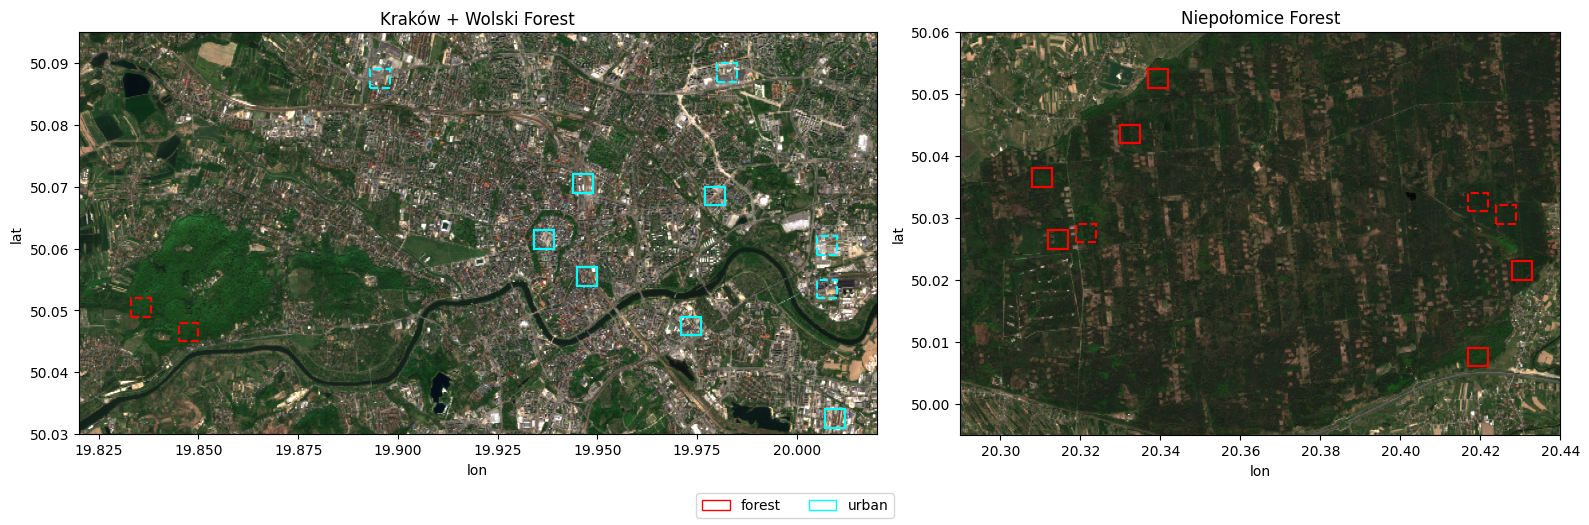

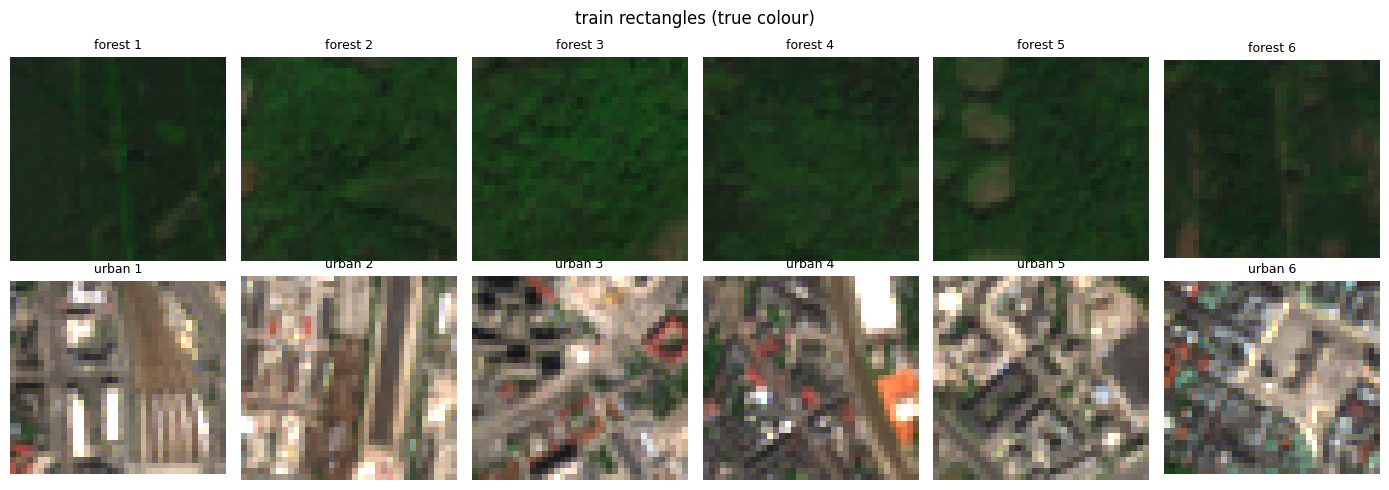

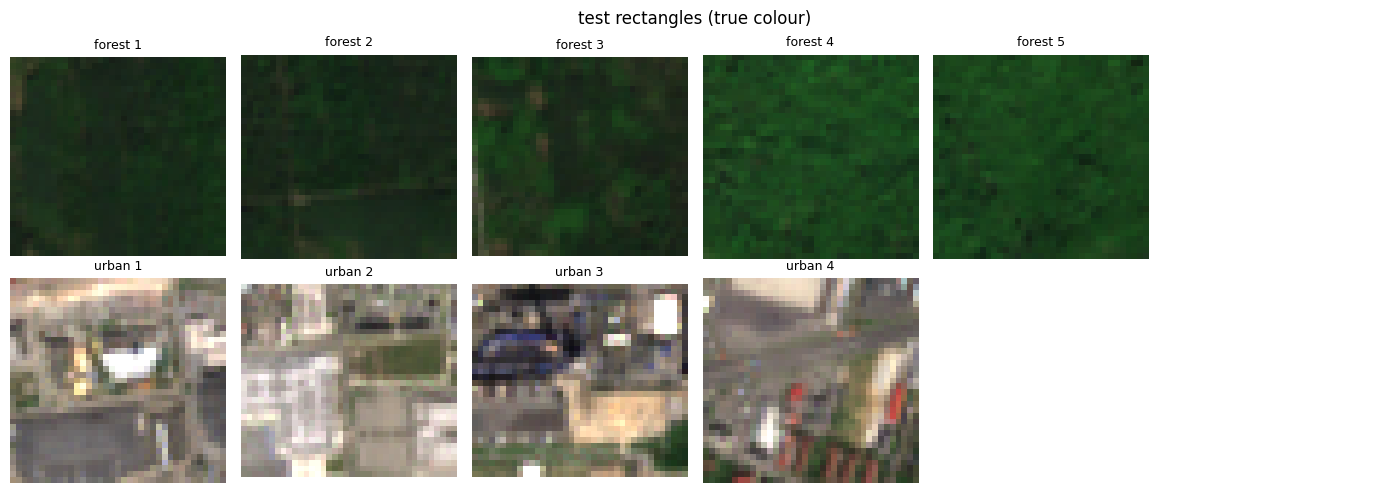

In [4]:
overviews = {"Kraków + Wolski Forest": [19.82, 50.03, 20.02, 50.095],
             "Niepołomice Forest":     [20.29, 49.995, 20.44, 50.06]}
fig, ax = mp.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1.33, 1]})
for a, (title, bb) in zip(ax, overviews.items()):
    ov = load_s2(bb, crs="EPSG:4326", resolution=0.0002)
    a.imshow(to_rgb(ov), extent=[bb[0], bb[2], bb[1], bb[3]], aspect=1.55)
    for split, ls in [("train", "-"), ("test", "--")]:
        for cls, col in [("forest", "red"), ("urban", "cyan")]:
            for r in ROIS[split][cls]:
                a.add_patch(Rectangle((r[0], r[1]), r[2] - r[0], r[3] - r[1], fill=False, ec=col, lw=1.6, ls=ls))
    a.set_xlim(bb[0], bb[2]); a.set_ylim(bb[1], bb[3]); a.set_title(title)
    a.set_xlabel("lon"); a.set_ylabel("lat")
fig.legend(handles=[Patch(fill=False, ec="red", label="forest"), Patch(fill=False, ec="cyan", label="urban")],
           loc="lower center", ncol=2)
mp.tight_layout(rect=(0, .05, 1, 1)); mp.show()

# Close-up of every rectangle
for split in ["train", "test"]:
    fig, ax = mp.subplots(2, 6, figsize=(14, 5))
    for r, cls in enumerate(["forest", "urban"]):
        for c in range(6):
            ax[r, c].axis("off")
            if c < len(cubes[split, cls]):
                ax[r, c].imshow(to_rgb(cubes[split, cls][c])); ax[r, c].set_title(f"{cls} {c + 1}", fontsize=9)
    mp.suptitle(f"{split} rectangles (true colour)"); mp.tight_layout(); mp.show()

## 1.2 Histograms and parametric models of the PDFs

### 1.2.1 Histograms of the training pixels

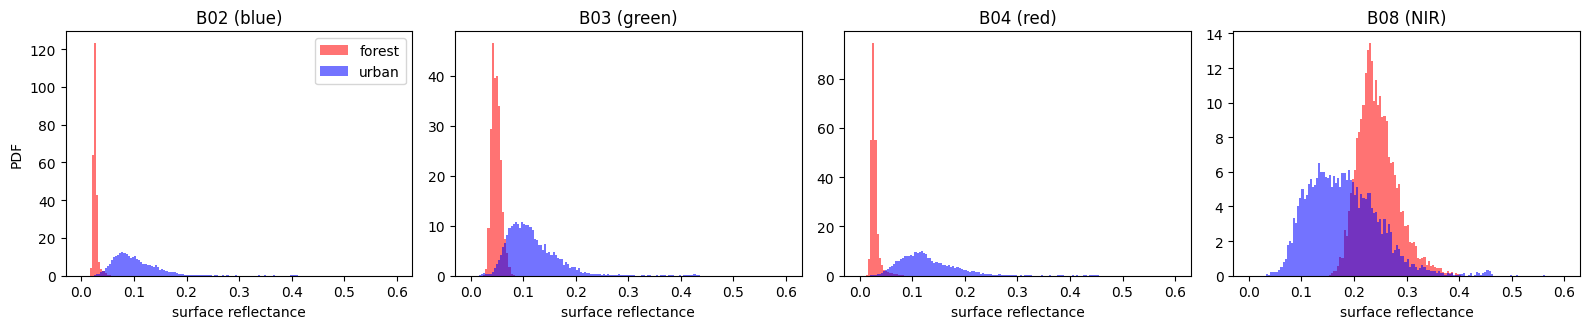

In [5]:
fig, ax = mp.subplots(1, 4, figsize=(16, 3.4))
for i, b in enumerate(S2_BANDS):
    ax[i].hist(Xf[:, i], bins=150, range=(0, 0.6), density=True, alpha=.55, color="red", label="forest")
    ax[i].hist(Xu[:, i], bins=150, range=(0, 0.6), density=True, alpha=.55, color="blue", label="urban")
    ax[i].set_title(BAND_LABEL[b]); ax[i].set_xlabel("surface reflectance")
ax[0].set_ylabel("PDF"); ax[0].legend(); mp.tight_layout(); mp.show()

**Observations:**
* **Visible bands (B02, B03, B04).** Forest is one narrow peak at very low reflectance, because chlorophyll absorbs blue and red light and the canopy is homogeneous. Urban is much wider, shifted to higher reflectance and right-skewed.
* **NIR:** both distributions are wide and overlap a lot.

### 1.2.2 Parametric models and parameter estimation (maximum likelihood)

**Model A, 1-D Gaussian on the red band B04**:
$$p(x\mid\omega_i)=\frac{1}{\sqrt{2\pi}\,\sigma_i}\exp\!\left(-\frac{(x-\mu_i)^2}{2\sigma_i^2}\right)$$

**Model B, 4-D multivariate Gaussian on $\mathbf{x}=[B02,B03,B04,B08]^T$:**
$$p(\mathbf{x}\mid\omega_i)=\frac{1}{(2\pi)^{d/2}|\boldsymbol\Sigma_i|^{1/2}}
\exp\!\left(-\tfrac12(\mathbf{x}-\boldsymbol\mu_i)^T\boldsymbol\Sigma_i^{-1}(\mathbf{x}-\boldsymbol\mu_i)\right),\qquad d=4$$

The bands are strongly correlated, so Model B uses a **full covariance matrix**, not four independent 1-D Gaussians.

**Maximum-likelihood estimates** from the $N_i$ training pixels of class $\omega_i$:
$$\hat{\boldsymbol\mu}_i=\frac1{N_i}\sum_{n}\mathbf{x}_n ,\qquad
\hat{\boldsymbol\Sigma}_i=\frac1{N_i}\sum_{n}(\mathbf{x}_n-\hat{\boldsymbol\mu}_i)(\mathbf{x}_n-\hat{\boldsymbol\mu}_i)^T$$

In [6]:
def fit_gaussian(X):
    X = X.reshape(len(X), -1)
    mu = X.mean(axis=0)
    D = X - mu
    return mu, D.T @ D / len(X)

def gaussian_logpdf(X, mu, Sigma):
    # log N(x | mu, Sigma) for every row of X
    X = X.reshape(len(X), -1)
    d = X.shape[1]
    L = np.linalg.cholesky(Sigma)                  # Sigma = L L^T
    z = np.linalg.solve(L, (X - mu).T)             # z = L^-1 (x - mu)
    maha2 = np.sum(z**2, axis=0)                   # squared Mahalanobis distance
    logdet = 2 * np.sum(np.log(np.diag(L)))        # log|Sigma|
    return -0.5 * (d * np.log(2 * np.pi) + logdet + maha2)

RED = S2_BANDS.index("B04")
params_A = (fit_gaussian(Xf[:, RED]), fit_gaussian(Xu[:, RED]))    # Model A
params_B = (fit_gaussian(Xf), fit_gaussian(Xu))                    # Model B

np.set_printoptions(precision=4, suppress=True)
print("Model A (B04):")
for name, (mu, S) in zip(CLASS_NAMES, params_A):
    print(f"  {name:6s}: mu = {mu[0]:.4f}   sigma = {np.sqrt(S[0, 0]):.4f}")
print("\nModel B (B02, B03, B04, B08):")
for name, (mu, S) in zip(CLASS_NAMES, params_B):
    sd = np.sqrt(np.diag(S))
    print(f"  {name}: mu = {mu}\n  sigma = {sd}\n  correlation matrix =\n{S / np.outer(sd, sd)}\n")

Model A (B04):
  forest: mu = 0.0281   sigma = 0.0075
  urban : mu = 0.1286   sigma = 0.0568

Model B (B02, B03, B04, B08):
  forest: mu = [0.0262 0.0487 0.0281 0.2451]
  sigma = [0.0041 0.0087 0.0075 0.0373]
  correlation matrix =
[[1.     0.4479 0.8968 0.2962]
 [0.4479 1.     0.4576 0.8081]
 [0.8968 0.4576 1.     0.24  ]
 [0.2962 0.8081 0.24   1.    ]]

  urban: mu = [0.1031 0.1171 0.1286 0.1798]
  sigma = [0.0472 0.0505 0.0568 0.0664]
  correlation matrix =
[[1.     0.9739 0.9325 0.6059]
 [0.9739 1.     0.9618 0.7022]
 [0.9325 0.9618 1.     0.6925]
 [0.6059 0.7022 0.6925 1.    ]]



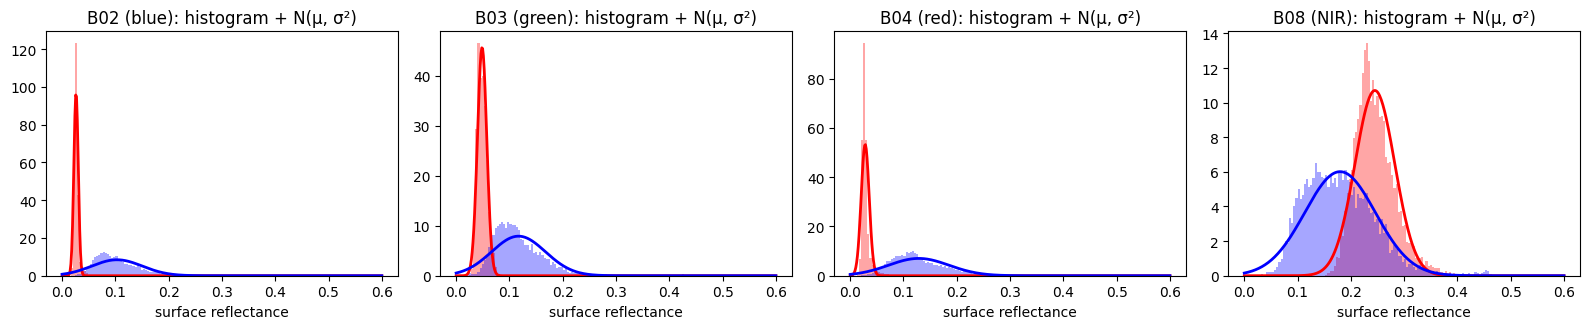

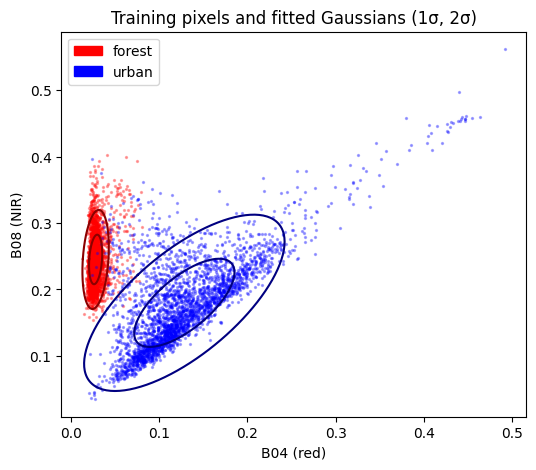

In [7]:
# Goodness of fit: histograms vs. fitted Gaussians (Model B)
xs = np.linspace(0, 0.6, 400)
fig, ax = mp.subplots(1, 4, figsize=(16, 3.4))
for i, b in enumerate(S2_BANDS):
    for Xc, (mu, S), col in [(Xf, params_B[0], "red"), (Xu, params_B[1], "blue")]:
        ax[i].hist(Xc[:, i], bins=150, range=(0, 0.6), density=True, alpha=.35, color=col)
        ax[i].plot(xs, np.exp(gaussian_logpdf(xs, mu[i:i+1], S[i:i+1, i:i+1])), color=col, lw=2)
    ax[i].set_title(f"{BAND_LABEL[b]}: histogram + N(μ, σ²)"); ax[i].set_xlabel("surface reflectance")
mp.tight_layout(); mp.show()

def ellipse(mu, S, k, i, j):
    t = np.linspace(0, 2 * np.pi, 200)
    w, V = np.linalg.eigh(S[np.ix_([i, j], [i, j])])
    return mu[[i, j]][:, None] + k * V @ (np.sqrt(w)[:, None] * np.vstack([np.cos(t), np.sin(t)]))

NIR = S2_BANDS.index("B08")
sf = Xf[rng.choice(len(Xf), min(3000, len(Xf)), replace=False)]
su = Xu[rng.choice(len(Xu), min(3000, len(Xu)), replace=False)]
fig, a = mp.subplots(figsize=(6, 5))
a.scatter(sf[:, RED], sf[:, NIR], s=2, c="red", alpha=.3); a.scatter(su[:, RED], su[:, NIR], s=2, c="blue", alpha=.3)
for (mu, S), col in zip(params_B, ["darkred", "navy"]):
    for k in (1, 2):
        e = ellipse(mu, S, k, RED, NIR); a.plot(e[0], e[1], color=col, lw=1.5)
a.set_xlabel("B04 (red)"); a.set_ylabel("B08 (NIR)"); a.legend(handles=LEGEND)
a.set_title("Training pixels and fitted Gaussians (1σ, 2σ)"); mp.show()

The fitted Gaussians follow the position, spread and orientation of both clusters. The approximation is worst in the long bright tail of the urban class. That does not matter much, because the decision depends only on where the two weighted PDFs cross, and that happens between the two clusters.

## 1.3 The Bayes test

**Bayes' rule:** $\;P(\omega_i\mid\mathbf{x})=\dfrac{p(\mathbf{x}\mid\omega_i)\,P(\omega_i)}{p(\mathbf{x})}$.

To minimise the error rate we choose the class with the larger posterior. $p(\mathbf{x})$ is the same for both classes, so the test is a **likelihood-ratio test**:

$$\Lambda(\mathbf{x})=\frac{p(\mathbf{x}\mid\text{forest})}{p(\mathbf{x}\mid\text{urban})}\;\underset{\text{urban}}{\overset{\text{forest}}{\gtrless}}\;\frac{P(\text{urban})}{P(\text{forest})}$$

For numerical stability we work with logarithms, using the **discriminant**

$$g(\mathbf{x})=\ln p(\mathbf{x}\mid\text{forest})-\ln p(\mathbf{x}\mid\text{urban})+\ln P(\text{forest})-\ln P(\text{urban}),\qquad
g(\mathbf{x})>0\Rightarrow\text{forest (red)},\quad g(\mathbf{x})\le0\Rightarrow\text{urban (blue)}.$$

**Priors.** We do not know in advance how much of a new scene is forest, so we use **equal priors**, $P(\text{forest})=P(\text{urban})=0.5$, which makes this a maximum-likelihood decision. The effect of other priors is shown in §1.4.

**Model A has an analytical threshold.** Setting $g(x)=0$ for two 1-D Gaussians gives $ax^2+bx+c=0$ with
$a=\frac{1}{2\sigma_u^2}-\frac{1}{2\sigma_f^2}$, $b=\frac{\mu_f}{\sigma_f^2}-\frac{\mu_u}{\sigma_u^2}$,
$c=\frac{\mu_u^2}{2\sigma_u^2}-\frac{\mu_f^2}{2\sigma_f^2}+\ln\frac{\sigma_u}{\sigma_f}+\ln\frac{P_f}{P_u}$.
The two variances are different, so there are **two thresholds**: very dark pixels end up in the wider urban class.

Model A: B04 thresholds = [0.006  0.0466]  -> forest if 0.0060 < B04 < 0.0466


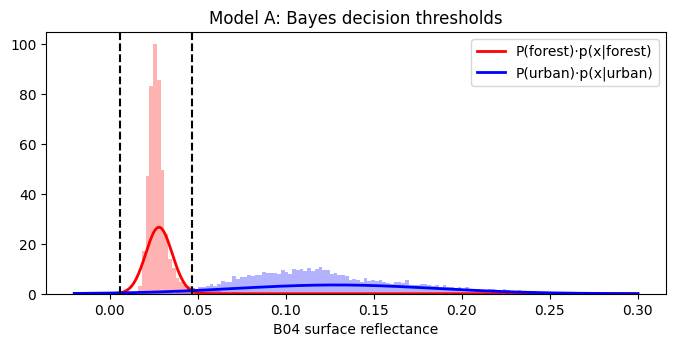

In [8]:
P_F, P_U = 0.5, 0.5

def bayes_discriminant(X, params, priors=(P_F, P_U)):
    (mf, Sf), (mu_, Su) = params
    return (gaussian_logpdf(X, mf, Sf) - gaussian_logpdf(X, mu_, Su)
            + np.log(priors[0]) - np.log(priors[1]))

def bayes_classify(X, params, priors=(P_F, P_U)):
    return np.where(bayes_discriminant(X, params, priors) > 0, FOREST, URBAN)

# analytical thresholds of Model A
(mf, vf), (mu_, vu) = [(m[0], S[0, 0]) for m, S in params_A]
a = 1 / (2 * vu) - 1 / (2 * vf)
b = mf / vf - mu_ / vu
c = mu_**2 / (2 * vu) - mf**2 / (2 * vf) + 0.5 * np.log(vu / vf) + np.log(P_F / P_U)
thr = np.sort(np.real(np.roots([a, b, c])))
print("Model A: B04 thresholds =", thr, " -> forest if", f"{thr[0]:.4f} < B04 < {thr[1]:.4f}")

xs = np.linspace(-0.02, 0.3, 500)
mp.figure(figsize=(8, 3.4))
mp.hist(Xf[:, RED], 150, range=(-0.02, 0.3), density=True, alpha=.3, color="red")
mp.hist(Xu[:, RED], 150, range=(-0.02, 0.3), density=True, alpha=.3, color="blue")
mp.plot(xs, P_F * np.exp(gaussian_logpdf(xs, *params_A[0])), "r", lw=2, label="P(forest)·p(x|forest)")
mp.plot(xs, P_U * np.exp(gaussian_logpdf(xs, *params_A[1])), "b", lw=2, label="P(urban)·p(x|urban)")
for t in thr: mp.axvline(t, color="k", ls="--")
mp.xlabel("B04 surface reflectance"); mp.legend(); mp.title("Model A: Bayes decision thresholds"); mp.show()

## 1.4 Results

### 1.4.1 Accuracy on the held-out test rectangles
These pixels have a known label and were not used for training, so they give an honest error estimate.

In [9]:
def confusion(y_true, y_pred):
    return np.array([[np.sum((y_true == t) & (y_pred == p)) for p in (0, 1)] for t in (0, 1)])

def report(name, y_true, y_pred, verbose=True):
    C = confusion(y_true, y_pred)
    acc = np.trace(C) / C.sum()
    if verbose:
        prec = np.diag(C) / np.maximum(C.sum(axis=0), 1); rec = np.diag(C) / np.maximum(C.sum(axis=1), 1)
        print(f"{name}\n  overall accuracy = {acc * 100:.2f} %\n  confusion matrix (rows = true, cols = pred) [forest, urban]:\n{C}")
        for k in (0, 1):
            print(f"  {CLASS_NAMES[k]:6s}: precision = {prec[k] * 100:.2f} %, recall = {rec[k] * 100:.2f} %")
    return acc

X_test = np.vstack([X["test", "forest"], X["test", "urban"]])
y_test = np.concatenate([np.full(len(X["test", "forest"]), FOREST), np.full(len(X["test", "urban"]), URBAN)])

acc_A = report("Bayes, Model A (B04 only)", y_test, bayes_classify(X_test[:, RED], params_A))
acc_B = report("Bayes, Model B (4 bands)", y_test, bayes_classify(X_test, params_B))

print("\nModel B, accuracy per test rectangle:")
for cls, lab in [("forest", FOREST), ("urban", URBAN)]:
    for k, cube in enumerate(cubes["test", cls]):
        Xr = cube.reshape(-1, 4); Xr = Xr[~np.isnan(Xr).any(axis=1)]
        print(f"  {cls} {k + 1}: {np.mean(bayes_classify(Xr, params_B) == lab) * 100:6.2f} %   bbox {ROIS['test'][cls][k]}")

Bayes, Model A (B04 only)
  overall accuracy = 98.18 %
  confusion matrix (rows = true, cols = pred) [forest, urban]:
[[6299  102]
 [ 109 5065]]
  forest: precision = 98.30 %, recall = 98.41 %
  urban : precision = 98.03 %, recall = 97.89 %
Bayes, Model B (4 bands)
  overall accuracy = 99.06 %
  confusion matrix (rows = true, cols = pred) [forest, urban]:
[[6342   59]
 [  50 5124]]
  forest: precision = 99.22 %, recall = 99.08 %
  urban : precision = 98.86 %, recall = 99.03 %

Model B, accuracy per test rectangle:
  forest 1:  99.28 %   bbox [20.424, 50.029, 20.429, 50.032]
  forest 2:  99.61 %   bbox [20.417, 50.031, 20.422, 50.034]
  forest 3:  96.42 %   bbox [20.319, 50.026, 20.324, 50.029]
  forest 4: 100.00 %   bbox [19.833, 50.049, 19.838, 50.052]
  forest 5: 100.00 %   bbox [19.845, 50.045, 19.85, 50.048]
  urban 1: 100.00 %   bbox [19.98, 50.087, 19.985, 50.09]
  urban 2: 100.00 %   bbox [20.005, 50.059, 20.01, 50.062]
  urban 3:  97.91 %   bbox [20.005, 50.052, 20.01, 50.055]


### 1.4.2 A new image
The scene is the western part of Kraków: the Wolski Forest, the districts Bielany, Przegorzały and Zwierzyniec, the Vistula and some fields. None of its pixels were used for training.

The scene also contains classes the classifier was not trained on, such as water, meadows and arable fields.
The first one is a two-class classifier.
In the second figure there is a reject option added.

new image: (456, 724, 4) -> 330144 pixels
Bayes classification time (both models): 0.14 s


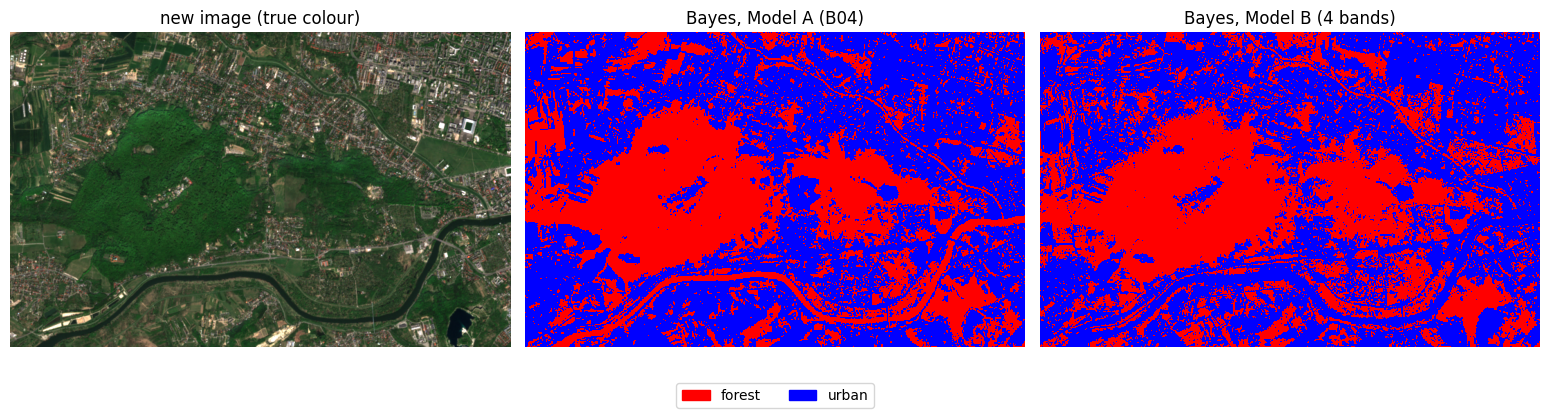

Model A: 42.3 % of the scene labelled forest
Model B: 45.1 % of the scene labelled forest


In [10]:
NEW_BB = [19.82, 50.035, 19.92, 50.075]                # western Kraków + Wolski Forest
new_img = load_s2(NEW_BB)
H, W, _ = new_img.shape
X_new = new_img.reshape(-1, 4)
valid = ~np.isnan(X_new).any(axis=1)
X_new = np.where(valid[:, None], X_new, 0)             # placeholder for no-data pixels
print("new image:", new_img.shape, "->", H * W, "pixels")

t0 = time.time()
pred_A = bayes_classify(X_new[:, RED], params_A).reshape(H, W)
pred_B = bayes_classify(X_new, params_B).reshape(H, W)
t_bayes = time.time() - t0
print(f"Bayes classification time (both models): {t_bayes:.2f} s")

def show_maps(maps, titles, img=new_img, figsize=None):
    n = len(maps) + 1
    fig, ax = mp.subplots(1, n, figsize=figsize or (5.2 * n, 4.2))
    ax[0].imshow(to_rgb(img)); ax[0].set_title("new image (true colour)")
    for a, m, t in zip(ax[1:], maps, titles):
        a.imshow(m, cmap=CMAP_CLS, vmin=0, vmax=1, interpolation="nearest"); a.set_title(t)
    for a in ax: a.axis("off")
    fig.legend(handles=LEGEND, loc="lower center", ncol=2); mp.tight_layout(rect=(0, .06, 1, 1)); mp.show()

show_maps([pred_A, pred_B], ["Bayes, Model A (B04)", "Bayes, Model B (4 bands)"])
for name, p in [("A", pred_A), ("B", pred_B)]:
    print(f"Model {name}: {np.mean(p == FOREST) * 100:.1f} % of the scene labelled forest")

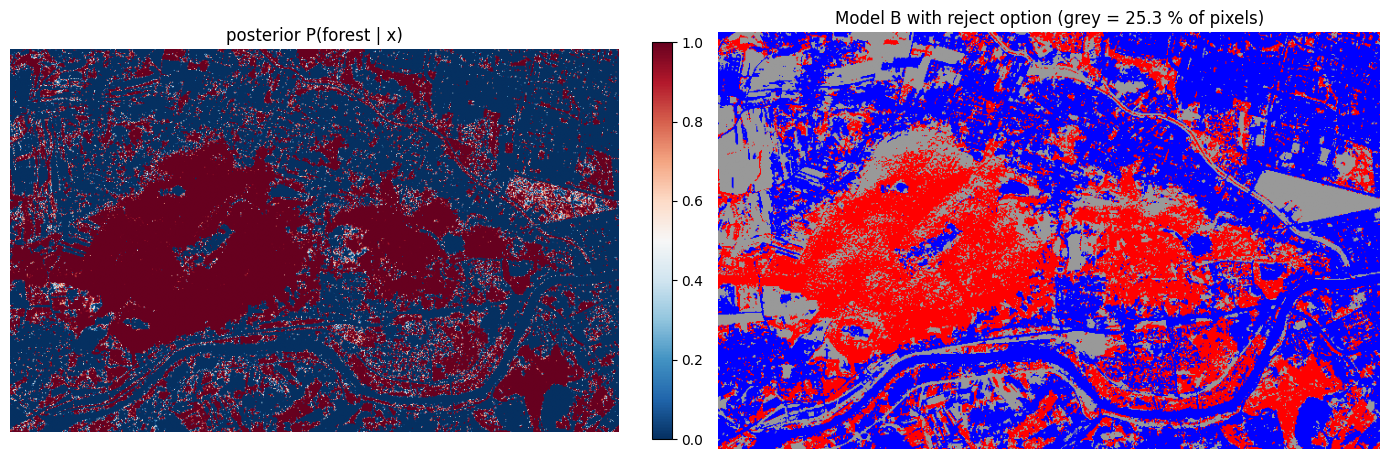

In [11]:
# Posterior probability and reject option (Model B)
g = bayes_discriminant(X_new, params_B)
post_forest = np.exp(-np.logaddexp(0, -g)).reshape(H, W)

def maha2(X, mu, S):
    z = np.linalg.solve(np.linalg.cholesky(S), (X - mu).T)
    return np.sum(z**2, axis=0)

CHI2_4_999 = 18.47
reject = ((maha2(X_new, *params_B[0]) > CHI2_4_999) & (maha2(X_new, *params_B[1]) > CHI2_4_999)).reshape(H, W)
rgb_rej = CMAP_CLS(pred_B.astype(float))[..., :3]; rgb_rej[reject] = 0.6

fig, ax = mp.subplots(1, 2, figsize=(14, 4.6))
im = ax[0].imshow(post_forest, cmap="RdBu_r", vmin=0, vmax=1); ax[0].set_title("posterior P(forest | x)")
mp.colorbar(im, ax=ax[0], fraction=.03)
ax[1].imshow(rgb_rej); ax[1].set_title(f"Model B with reject option (grey = {reject.mean() * 100:.1f} % of pixels)")
for a in ax: a.axis("off")
mp.tight_layout(); mp.show()

In [12]:
# Effect of the prior P(forest) on the new image
for pf in [0.1, 0.3, 0.5, 0.7, 0.9]:
    p = bayes_classify(X_new, params_B, priors=(pf, 1 - pf))
    print(f"P(forest) = {pf:.1f}: pixels labelled forest = {np.mean(p == FOREST) * 100:5.2f} %,  "
          f"test-rectangle accuracy = {np.mean(bayes_classify(X_test, params_B, (pf, 1 - pf)) == y_test) * 100:.2f} %")

P(forest) = 0.1: pixels labelled forest = 41.25 %,  test-rectangle accuracy = 98.95 %
P(forest) = 0.3: pixels labelled forest = 43.68 %,  test-rectangle accuracy = 99.02 %
P(forest) = 0.5: pixels labelled forest = 45.07 %,  test-rectangle accuracy = 99.06 %
P(forest) = 0.7: pixels labelled forest = 46.39 %,  test-rectangle accuracy = 99.07 %
P(forest) = 0.9: pixels labelled forest = 48.31 %,  test-rectangle accuracy = 99.07 %


### 1.5 Discussion of the Bayes classifier

**Steps**
1. **Training areas.** 6 forest and 6 urban hand-crafted rectangles (7 733 and 7 764 pixels). Another 5 + 4 rectangles (11 575 pixels) were held out for testing.
2. **Histograms.** In the visible bands forest is one narrow peak at low reflectance, while urban is wider, brighter and right-skewed. In NIR both classes are wide and overlap.
3. **Parametric model.** Gaussian PDFs with maximum-likelihood parameters: $\mu, \sigma$ of B04 for Model A, and the mean vector $\boldsymbol\mu$ and full covariance matrix $\boldsymbol\Sigma$ of the 4 bands for Model B.
4. **Bayes test.** Every pixel gets $g(\mathbf{x}) = \ln p(\mathbf{x}|f) - \ln p(\mathbf{x}|u) + \ln\frac{P_f}{P_u}$ and is coloured red if $g > 0$ and blue otherwise (equal priors).

**Results**
* **Test accuracy.** Model A (B04 only) reaches **98.2 %** and Model B (4 bands) **99.1 %**. Most test rectangles are classified 99–100 % correctly. The worst one is a Niepołomice forest rectangle (96.4 %).
* **Different forest type.** The training forest is almost entirely from the Niepołomice Forest. The two Wolski Forest test rectangles are still classified **100 %** correctly, so the model is not limited to the forest it was trained on.
* **Model A** has two thresholds: a pixel is forest only if $0.006 < B04 < 0.047$. Very dark pixels below the lower threshold go to the wider urban Gaussian. A single band is not enough for water, as the Vistula river is dark in B04, so Model A labels most of water pixels as forest. Model B doesn't label them as forest, because it also uses the green and NIR bands.
* **New image.** The Wolski Forest and the larger green areas are red, and the built-up districts are blue. The map contains some salt-and-pepper noise, because every pixel is classified independently, without its neighbours.
* **Classes not in the training data.** Without the reject option, Model B has to put every grey pixel into one of the two classes, so the split tells us little about what these pixels really are. The posterior is often close to 0 or 1 even here, because it only compares the two classes with each other and does not say whether either of them fits well.
* **Priors.** Changing $P(\text{forest})$ from 0.1 to 0.9 changes the forest share of the new image only from 41 % to 48 %, and the test accuracy by about 0.1 percentage points.

---
# Part 2: k-Nearest-Neighbours classifier

## 2.1 Design

- **Features.** Each pixel is a vector $\mathbf{x} = [B02, B03, B04, B08]$ of surface reflectances.
- **Training set.** 2 000 random pixels per class are taken from the training rectangles. k-NN has to compare every pixel with every stored sample, so a subsample keeps the run time reasonable. Equal numbers per class correspond to equal priors.
- **Training.** There is no real training: the classifier only stores the labelled samples.
- **Distance.** For a new pixel $\mathbf{x}$ the Euclidean distance to every training sample is computed: $d(\mathbf{x}, \mathbf{x}_n) = \lVert \mathbf{x} - \mathbf{x}_n \rVert_2$. In the code it is vectorised as $\lVert a-b \rVert^2 = \lVert a \rVert^2 + \lVert b \rVert^2 - 2a^Tb$, so a single matrix product replaces the loops.
- **Nearest neighbours.** For every pixel the k training samples with the smallest distance are selected (argpartition, and then only these k are sorted).
- **Majority vote.** The pixel gets the class that occurs most often among its k neighbours and is coloured red (forest) or blue (urban).
- **Ties.** With 2 classes and odd k (1, 3, 5) a tie cannot happen.
- **Check.** The implementation is first tested on a small toy example.

In [13]:
N_PER_CLASS = 2000
X_train = np.vstack([Xf[rng.choice(len(Xf), min(N_PER_CLASS, len(Xf)), replace=False)],
                     Xu[rng.choice(len(Xu), min(N_PER_CLASS, len(Xu)), replace=False)]])
y_train = np.concatenate([np.full(min(N_PER_CLASS, len(Xf)), FOREST), np.full(min(N_PER_CLASS, len(Xu)), URBAN)])
print("k-NN training set:", X_train.shape, " class counts:", np.bincount(y_train))

def pairwise_sq_dist(A, B):
    return np.maximum((A**2).sum(1)[:, None] + (B**2).sum(1)[None, :] - 2 * A @ B.T, 0)

def knn_neighbours(X_query, X_train, k_max, batch=4096):
    out = np.empty((len(X_query), k_max), dtype=int)
    for s in range(0, len(X_query), batch):
        D = pairwise_sq_dist(X_query[s:s + batch], X_train)
        part = np.argpartition(D, k_max - 1, axis=1)[:, :k_max]
        order = np.argsort(np.take_along_axis(D, part, axis=1), axis=1)
        out[s:s + batch] = np.take_along_axis(part, order, axis=1)
    return out

def knn_vote(neigh, y_train, k):
    return np.where(y_train[neigh[:, :k]].sum(axis=1) > k / 2, URBAN, FOREST)

def knn_classify(X_query, X_train, y_train, k):
    return knn_vote(knn_neighbours(X_query, X_train, k), y_train, k)

Xt = np.array([[0, 0], [.1, 0], [1, 1], [.9, 1], [.2, .2]]); yt = np.array([0, 0, 1, 1, 1])
q = np.array([[.05, 0], [.95, 1], [.15, .15]])
print("toy k=1:", knn_classify(q, Xt, yt, 1), "(expected [0 1 1])")
print("toy k=3:", knn_classify(q, Xt, yt, 3), "(expected [0 1 0]: 3rd query has neighbours [.2,.2]=1, [.1,0]=0, [0,0]=0)")

k-NN training set: (4000, 4)  class counts: [2000 2000]
toy k=1: [0 1 1] (expected [0 1 1])
toy k=3: [0 1 0] (expected [0 1 0]: 3rd query has neighbours [.2,.2]=1, [.1,0]=0, [0,0]=0)


## 2.2 Results

We search the 5 nearest neighbours **once** and read the k = 1, 3, 5 votes from the same sorted list. This gives exactly the same result as running the classifier three times.

In [14]:
NEIGH_TEST = knn_neighbours(X_test, X_train, 5)
acc_knn = {k: report(f"k-NN, k = {k} (test rectangles)", y_test, knn_vote(NEIGH_TEST, y_train, k)) for k in (1, 3, 5)}

k-NN, k = 1 (test rectangles)
  overall accuracy = 98.83 %
  confusion matrix (rows = true, cols = pred) [forest, urban]:
[[6363   38]
 [  98 5076]]
  forest: precision = 98.48 %, recall = 99.41 %
  urban : precision = 99.26 %, recall = 98.11 %
k-NN, k = 3 (test rectangles)
  overall accuracy = 98.80 %
  confusion matrix (rows = true, cols = pred) [forest, urban]:
[[6358   43]
 [  96 5078]]
  forest: precision = 98.51 %, recall = 99.33 %
  urban : precision = 99.16 %, recall = 98.14 %
k-NN, k = 5 (test rectangles)
  overall accuracy = 98.82 %
  confusion matrix (rows = true, cols = pred) [forest, urban]:
[[6360   41]
 [  96 5078]]
  forest: precision = 98.51 %, recall = 99.36 %
  urban : precision = 99.20 %, recall = 98.14 %


k-NN neighbour search for 330,144 pixels vs 4,000 training samples: 39.3 s (Bayes: 0.14 s)


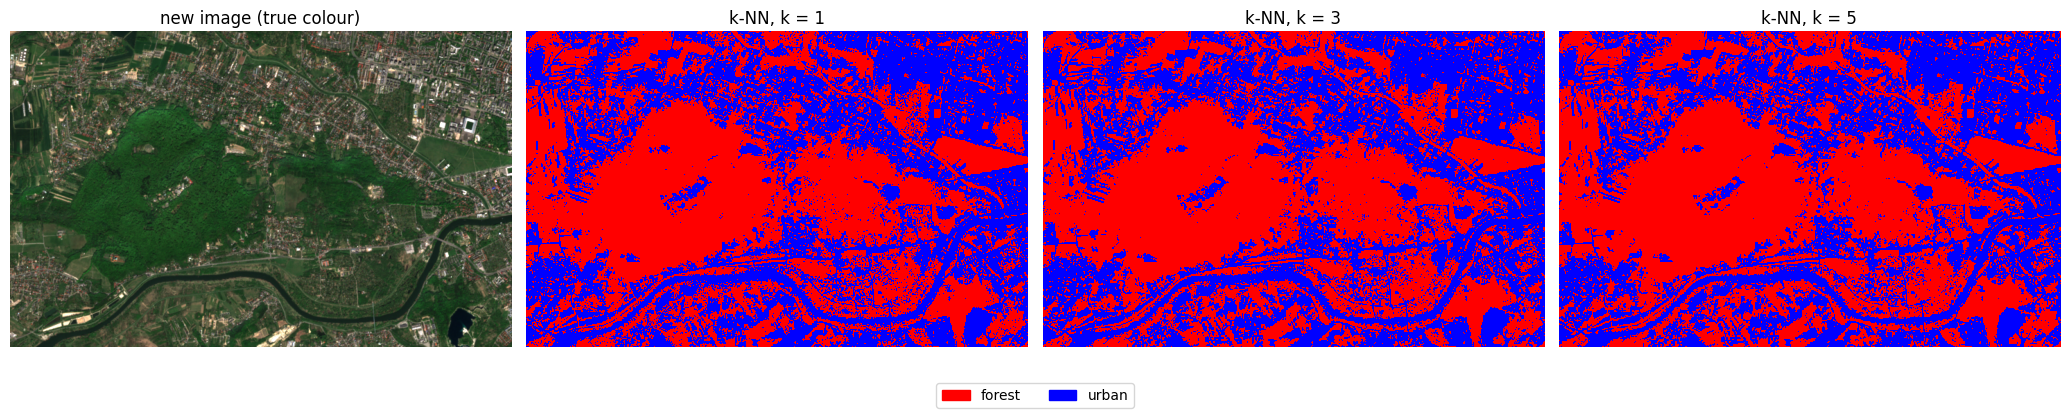

In [15]:
t0 = time.time()
NEIGH_NEW = knn_neighbours(X_new, X_train, 5)
t_knn = time.time() - t0
print(f"k-NN neighbour search for {len(X_new):,} pixels vs {len(X_train):,} training samples: {t_knn:.1f} s "
      f"(Bayes: {t_bayes:.2f} s)")
pred_knn = {k: knn_vote(NEIGH_NEW, y_train, k).reshape(H, W) for k in (1, 3, 5)}
show_maps([pred_knn[k] for k in (1, 3, 5)], [f"k-NN, k = {k}" for k in (1, 3, 5)])

## 2.3 Changing k: 1 → 3 → 5

To describe the differences with numbers and not only by eye we measure:
* **accuracy on the test rectangles**;
* **training accuracy**;
* the **salt-and-pepper index**;
* the **share of pixels that change label** between two values of k;
* **zoomed crops** and the **decision regions** in the (red, NIR) feature plane.

In [16]:
def speckle_index(m):
    # fraction of pixels that disagree with the majority of their 3x3 neighbourhood
    P = np.pad(m, 1, mode="edge")
    s = sum(P[i:i + m.shape[0], j:j + m.shape[1]] for i in range(3) for j in range(3))
    return np.mean((s >= 5).astype(int) != m)

NEIGH_TR = knn_neighbours(X_train, X_train, 5)          # each training point is its own 1st neighbour
rows = {}
for k in (1, 3, 5):
    rows[f"k-NN k={k}"] = (np.mean(knn_vote(NEIGH_TR, y_train, k) == y_train), acc_knn[k],
                           speckle_index(pred_knn[k]), np.mean(pred_knn[k] == FOREST))
rows["Bayes (4 bands)"] = (np.mean(bayes_classify(X_train, params_B) == y_train), acc_B,
                           speckle_index(pred_B), np.mean(pred_B == FOREST))
print(f"{'classifier':16s} {'train acc':>10s} {'test acc':>10s} {'speckle':>9s} {'% forest':>9s}")
for n, (tr, te, sp, pf) in rows.items():
    print(f"{n:16s} {tr * 100:9.2f}% {te * 100:9.2f}% {sp * 100:8.2f}% {pf * 100:8.1f}%")

print("\nShare of pixels of the new image whose label changes:")
for a_, b_ in [(1, 3), (3, 5), (1, 5)]:
    print(f"  k={a_} vs k={b_}: {np.mean(pred_knn[a_] != pred_knn[b_]) * 100:.2f} %")
print(f"  k=5 vs Bayes: {np.mean(pred_knn[5] != pred_B) * 100:.2f} %")

classifier        train acc   test acc   speckle  % forest
k-NN k=1            100.00%     98.83%     7.58%     54.6%
k-NN k=3             99.83%     98.80%     6.45%     55.4%
k-NN k=5             99.48%     98.82%     5.91%     56.8%
Bayes (4 bands)      99.35%     99.06%     6.93%     45.1%

Share of pixels of the new image whose label changes:
  k=1 vs k=3: 4.45 %
  k=3 vs k=5: 3.12 %
  k=1 vs k=5: 5.73 %
  k=5 vs Bayes: 12.35 %


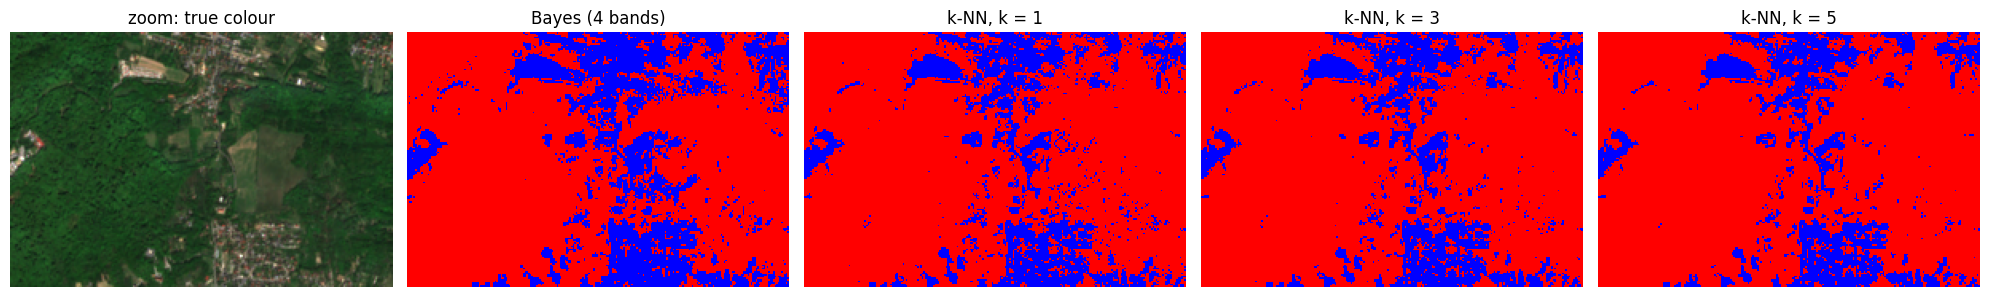

In [17]:
# Zoom on the forest edge / suburb transition
ZR, ZC = slice(H // 2 - 80, H // 2 + 80), slice(W // 2 - 120, W // 2 + 120)
fig, ax = mp.subplots(1, 5, figsize=(20, 3.8))
ax[0].imshow(to_rgb(new_img[ZR, ZC])); ax[0].set_title("zoom: true colour")
ax[1].imshow(pred_B[ZR, ZC], cmap=CMAP_CLS, vmin=0, vmax=1, interpolation="nearest"); ax[1].set_title("Bayes (4 bands)")
for a, k in zip(ax[2:], (1, 3, 5)):
    a.imshow(pred_knn[k][ZR, ZC], cmap=CMAP_CLS, vmin=0, vmax=1, interpolation="nearest"); a.set_title(f"k-NN, k = {k}")
for a in ax: a.axis("off")
mp.tight_layout(); mp.show()

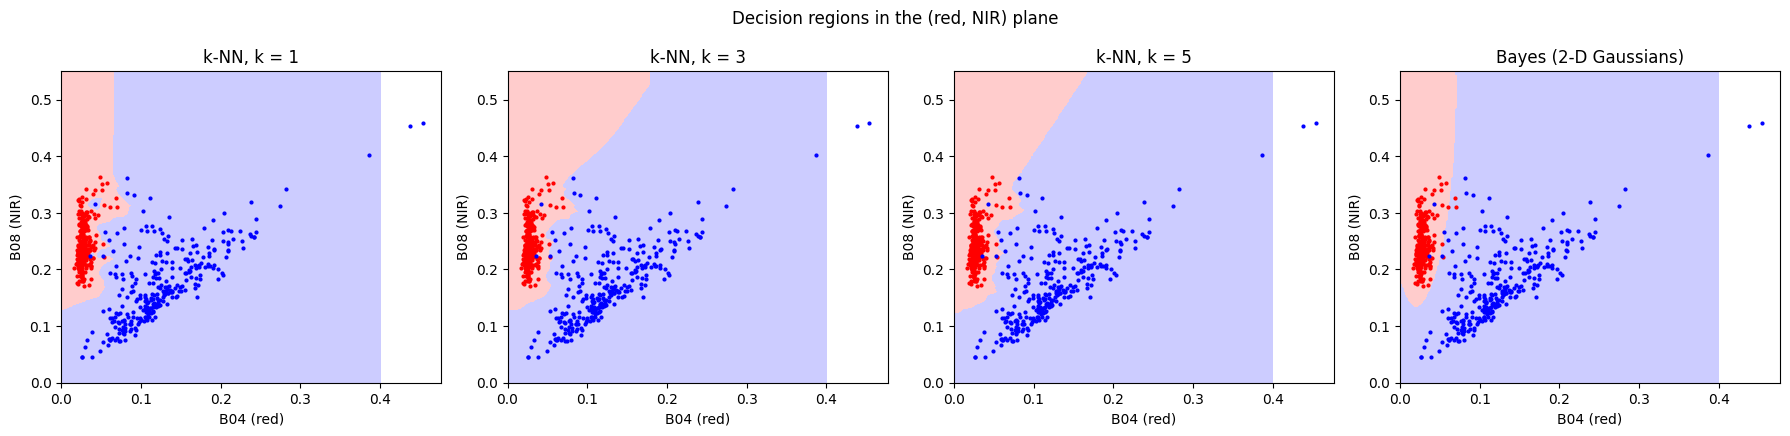

In [18]:
# Decision regions in the (red, NIR) plane. They are drawn for a 2-D classifier, because 4-D regions
# cannot be plotted. A small training sample (300 per class) makes the effect of k clearly visible.
n2 = 300
X2 = np.vstack([Xf[rng.choice(len(Xf), n2, replace=False)][:, [RED, NIR]],
                Xu[rng.choice(len(Xu), n2, replace=False)][:, [RED, NIR]]])
y2 = np.concatenate([np.zeros(n2, int), np.ones(n2, int)])
gx, gy = np.meshgrid(np.linspace(0, 0.4, 250), np.linspace(0, 0.55, 250))
grid = np.c_[gx.ravel(), gy.ravel()]
NG = knn_neighbours(grid, X2, 5)
params_2d = (fit_gaussian(Xf[:, [RED, NIR]]), fit_gaussian(Xu[:, [RED, NIR]]))

fig, ax = mp.subplots(1, 4, figsize=(18, 4.4))
panels = [(knn_vote(NG, y2, k), f"k-NN, k = {k}") for k in (1, 3, 5)] + [(bayes_classify(grid, params_2d), "Bayes (2-D Gaussians)")]
for a, (z, t) in zip(ax, panels):
    a.contourf(gx, gy, z.reshape(gx.shape), levels=[-.5, .5, 1.5], colors=["#ffcccc", "#ccccff"])
    a.scatter(X2[y2 == 0, 0], X2[y2 == 0, 1], s=4, c="red"); a.scatter(X2[y2 == 1, 0], X2[y2 == 1, 1], s=4, c="blue")
    a.set_title(t); a.set_xlabel("B04 (red)"); a.set_ylabel("B08 (NIR)")
mp.suptitle("Decision regions in the (red, NIR) plane"); mp.tight_layout(); mp.show()

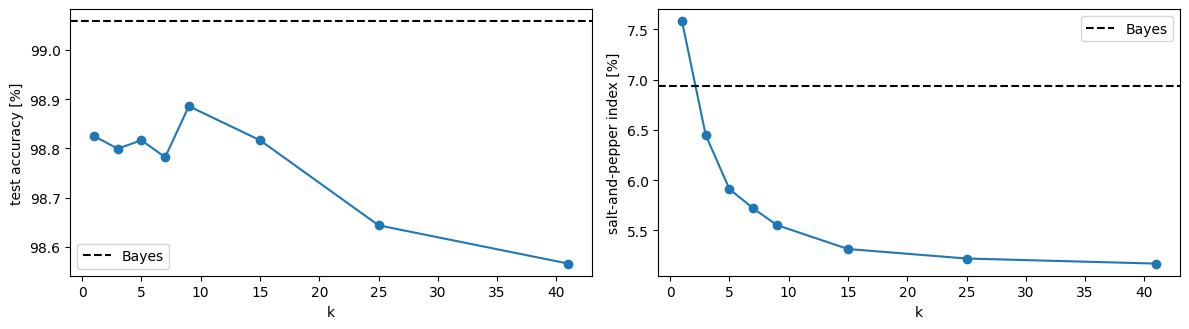

k =  1: test accuracy 98.83 %, speckle 7.58 %
k =  3: test accuracy 98.80 %, speckle 6.45 %
k =  5: test accuracy 98.82 %, speckle 5.91 %
k =  7: test accuracy 98.78 %, speckle 5.72 %
k =  9: test accuracy 98.89 %, speckle 5.55 %
k = 15: test accuracy 98.82 %, speckle 5.31 %
k = 25: test accuracy 98.64 %, speckle 5.22 %
k = 41: test accuracy 98.57 %, speckle 5.17 %


In [19]:
# Test accuracy and map noise for a wider range of k
ks = [1, 3, 5, 7, 9, 15, 25, 41]
NT = knn_neighbours(X_test, X_train, max(ks)); NN = knn_neighbours(X_new, X_train, max(ks))
acc_k = [np.mean(knn_vote(NT, y_train, k) == y_test) for k in ks]
spk_k = [speckle_index(knn_vote(NN, y_train, k).reshape(H, W)) for k in ks]
fig, ax = mp.subplots(1, 2, figsize=(12, 3.4))
ax[0].plot(ks, np.array(acc_k) * 100, "o-"); ax[0].axhline(acc_B * 100, color="k", ls="--", label="Bayes")
ax[0].set_xlabel("k"); ax[0].set_ylabel("test accuracy [%]"); ax[0].legend()
ax[1].plot(ks, np.array(spk_k) * 100, "o-"); ax[1].axhline(speckle_index(pred_B) * 100, color="k", ls="--", label="Bayes")
ax[1].set_xlabel("k"); ax[1].set_ylabel("salt-and-pepper index [%]"); ax[1].legend()
mp.tight_layout(); mp.show()
for k, a_, s_ in zip(ks, acc_k, spk_k): print(f"k = {k:2d}: test accuracy {a_ * 100:.2f} %, speckle {s_ * 100:.2f} %")

### Comments on k = 1, 3, 5

| | k = 1 | k = 3 | k = 5 |
|---|---|---|---|
| training accuracy | 100.00 % | 99.83 % | 99.48 % |
| test accuracy | 98.83 % | 98.80 % | 98.82 % |
| salt-and-pepper index | 7.6 % | 6.5 % | 5.9 % |
| pixels labelled forest | 54.6 % | 55.4 % | 56.8 % |

- **k = 1** memorises the training set: training accuracy is 100 %, because every training pixel is its own nearest neighbour. The decision boundary is jagged and the map is the noisiest.
- **Larger k** lets several neighbours vote, so single atypical training pixels are outvoted. The boundary becomes smoother and the map less noisy. 4.5 % of the pixels change label between k = 1 and 3, and 3.1 % between k = 3 and 5.
- **Test accuracy does not change**: The test rectangles are pure, so all k give the same vote there. The differences appear only in mixed pixels of the real image, such as forest edges and gardens.
- **Unknown classes.** Meadows and fields are labelled forest more often as k grows (83 % for k = 1, 88 % for k = 5), because their nearest neighbours are forest pixels.
- **Run time** is the same for every k, because the expensive part is computing the distances.

---
# 3. Bayes vs. k-NN: summary

In [20]:
print(f"{'method':24s} {'test accuracy':>14s} {'speckle (new image)':>20s}")
for n, a_, s_ in [("Bayes, Model A (B04)", acc_A, speckle_index(pred_A)), ("Bayes, Model B (4 bands)", acc_B, speckle_index(pred_B)),
                  ("k-NN, k = 1", acc_knn[1], speckle_index(pred_knn[1])), ("k-NN, k = 3", acc_knn[3], speckle_index(pred_knn[3])),
                  ("k-NN, k = 5", acc_knn[5], speckle_index(pred_knn[5]))]:
    print(f"{n:24s} {a_ * 100:13.2f}% {s_ * 100:19.2f}%")
print(f"\nclassification time of the new image: Bayes {t_bayes:.2f} s, k-NN {t_knn:.1f} s")

# How do the classifiers label pixels of the classes they were NOT trained on?
water = (new_img[..., 1] - new_img[..., 3]) / (new_img[..., 1] + new_img[..., 3] + 1e-6) > 0      # NDWI > 0
print(f"\nPixels rejected by the Bayes reject option (§1.4.2): {reject.mean() * 100:.1f} % of the scene "
      f"(mostly meadows and fields), water: {water.mean() * 100:.1f} %")
print(f"{'method':24s} {'% forest among rejected':>24s} {'% forest among water':>21s}")
for n, p in [("Bayes, Model A (B04)", pred_A), ("Bayes, Model B (4 bands)", pred_B),
             ("k-NN, k = 1", pred_knn[1]), ("k-NN, k = 5", pred_knn[5])]:
    print(f"{n:24s} {np.mean(p[reject] == FOREST) * 100:23.1f}% {np.mean(p[water] == FOREST) * 100:20.1f}%")

method                    test accuracy  speckle (new image)
Bayes, Model A (B04)             98.18%                4.97%
Bayes, Model B (4 bands)         99.06%                6.93%
k-NN, k = 1                      98.83%                7.58%
k-NN, k = 3                      98.80%                6.45%
k-NN, k = 5                      98.82%                5.91%

classification time of the new image: Bayes 0.14 s, k-NN 39.3 s

Pixels rejected by the Bayes reject option (§1.4.2): 25.3 % of the scene (mostly meadows and fields), water: 1.9 %
method                    % forest among rejected  % forest among water
Bayes, Model A (B04)                        45.8%                 85.8%
Bayes, Model B (4 bands)                    57.7%                  0.0%
k-NN, k = 1                                 83.1%                  0.0%
k-NN, k = 5                                 87.5%                  0.0%


| | Bayes (Gaussian) | k-NN |
|---|---|---|
| Model of $p(\mathbf{x}\mid\omega)$ | parametric: $\boldsymbol\mu,\boldsymbol\Sigma$ (14 numbers per class for 4 bands) | non-parametric: the training samples themselves |
| Training | estimate the parameters (instant) | store the samples |
| Classification of the new image | 0.13 s | 30 s (4 000 stored samples) |
| Test accuracy | 99.1 % | 98.8 % (k = 1, 3, 5) |
| Decision boundary | quadric surface (quadratic discriminant), smooth | any shape, smoothness controlled by k |
| Unknown classes | can be detected (reject option via Mahalanobis distance); without it, they are split between the two classes (here 58 % forest) | always assigned to the class of the nearest samples (here 83–88 % forest) |

**Conclusion.** Both classifiers work well on pure forest and urban areas: about 99 % of the test pixels are classified correctly. The two classes are far apart in the red and NIR bands and both are roughly Gaussian, so the Bayes classifier works as well as k-NN. It is also much faster (0.13 s vs 30 s). Changing k in k-NN mostly makes the map less noisy and does not really change the accuracy. In the new image, most errors come from meadows, fields and water, which were not in the training data, and probably also from mixed pixels at 10 m resolution. To improve the result we would need more classes and to take neighbouring pixels into account.